In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
# Read the Variants data from MongoDB
# The connection string may change based on AWS EC2 allocation
import pymongo
client = pymongo.MongoClient("mongodb://ec2-52-91-54-55.compute-1.amazonaws.com:27017/")

# Connect to the database "CROO"
db = client["CROO"]

# Connect to the collection "Variants" and load the data
collection = db["Variants"]
# find the documents with a matching Run_Batch field of "Expanded_Baseline"
batch = "Firesat_Baseline_24hr"
variants_df = pd.DataFrame(list(collection.find({"Run_Batch": batch})))
print(len(variants_df))
variants_df.head()

1


,_id,Variant_name,Run_Batch,Variant_path,Simulation,FSW,date_created,date_loaded,Simulation_rows,FSW_rows,Simulation_columns,FSW_columns,description
0,68b1f98ab07f82432104e5f2,1_0.0_0,Firesat_Baseline_24hr,Firesat_Baseline_24hr/FireSat_baseline_updated...,SIM_Output.csv,FSW_Output.csv,2025-08-29T18:48:39.493612,2025-08-29T19:03:38.381937,86402,86402,69,134,


In [16]:
# write the DataFrame to a local CSV file
variants_df.to_csv("./data/raw/baseline/long_variants_data.csv", index=False)

In [17]:
# Read the FSW data from MongoDB
fsw_collection = db["FSW"]
fsw_df = pd.DataFrame(list(fsw_collection.find({"Run_Batch": batch})))

In [18]:
fsw_df.shape

(86402, 135)

In [19]:
import math
# Create Longitude(deg) from Longitude(rad) and Latitude(deg) from Latitude(rad)
fsw_df['Longitude(deg)'] = fsw_df['Longitude(rad)'] * (180 / math.pi)
fsw_df['Latitude(deg)'] = fsw_df['Latitude(rad)'] * (180 / math.pi)

In [20]:
import cartopy.crs as ccrs
def plot_orbits(df, title):
    # Create figure
    fig, ax = plt.subplots(figsize=(20, 12), subplot_kw={'projection': ccrs.PlateCarree()})

    # Add background map
    ax.stock_img()

    # Create a colormap from unique strings
    unique_categories = list(set(df['Variant']))  # Get unique labels
    cmap = plt.colormaps['tab10']  # Use the new colormap access method
    color_map = {cat: cmap(i / len(unique_categories)) for i, cat in enumerate(unique_categories)}  # Map labels to colors
    colors = [color_map[cat] for cat in df['Variant']]

    # Scatter plot
    sc = ax.scatter(
        df['Longitude(deg)'], df['Latitude(deg)'],
        s=.1,  # Marker size
        color=colors,
        alpha=0.7
    )

    if len(color_map.items()) < 10:
        # Add legend for colors
        legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label=cat, markerfacecolor=color, markersize=5) for cat, color in color_map.items()]
        ax.legend(handles=legend_elements, loc='upper right', title='Variant')

    # Add title
    plt.title(title)

    # Show the plot
    plt.show()

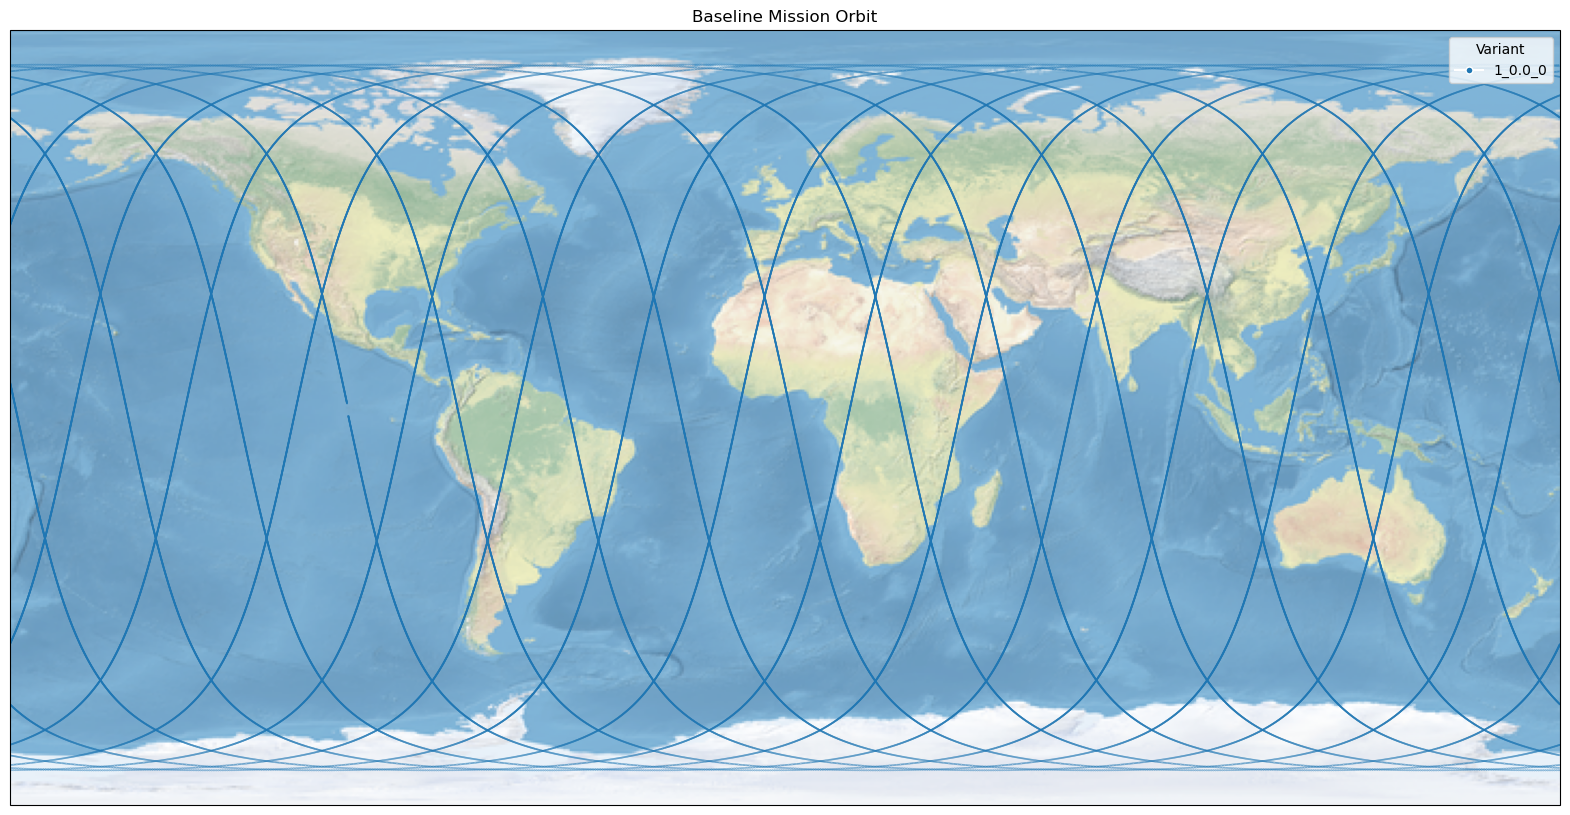

In [21]:
plot_orbits(fsw_df, "Baseline Mission Orbit")

In [24]:
import cartopy.crs as ccrs
def plot_orbits(df, title):
    # Create figure
    fig, ax = plt.subplots(figsize=(20, 12), subplot_kw={'projection': ccrs.PlateCarree()})

    # Add background map
    ax.stock_img()

    # Create a colormap from RawPrimaryGenericPointData[0]() unique values
    unique_primary_points = list(set(df['RawPrimaryGenericPointData[0]()']))  # Get unique labels
    cmap = plt.colormaps['tab10']  # Use the new colormap access method
    color_map = {cat: cmap(i / len(unique_primary_points)) for i, cat in enumerate(unique_primary_points)}  # Map labels to colors
    colors = [color_map[cat] for cat in df['RawPrimaryGenericPointData[0]()']]

    # Scatter plot
    sc = ax.scatter(
        df['Longitude(deg)'], df['Latitude(deg)'],
        s=10,  # Marker size
        color=colors,
        alpha=0.7
    )

    # if len(color_map.items()) < 10:
    #     # Add legend for colors
    #     legend_elements = [plt.Line2D([0], [0], marker='o', color='w', label=cat, markerfacecolor=color, markersize=5) for cat, color in color_map.items()]
    #     ax.legend(handles=legend_elements, loc='upper right', title='Baseline Mission Pointing')

    # Add title
    plt.title(title)

    # Show the plot
    plt.show()

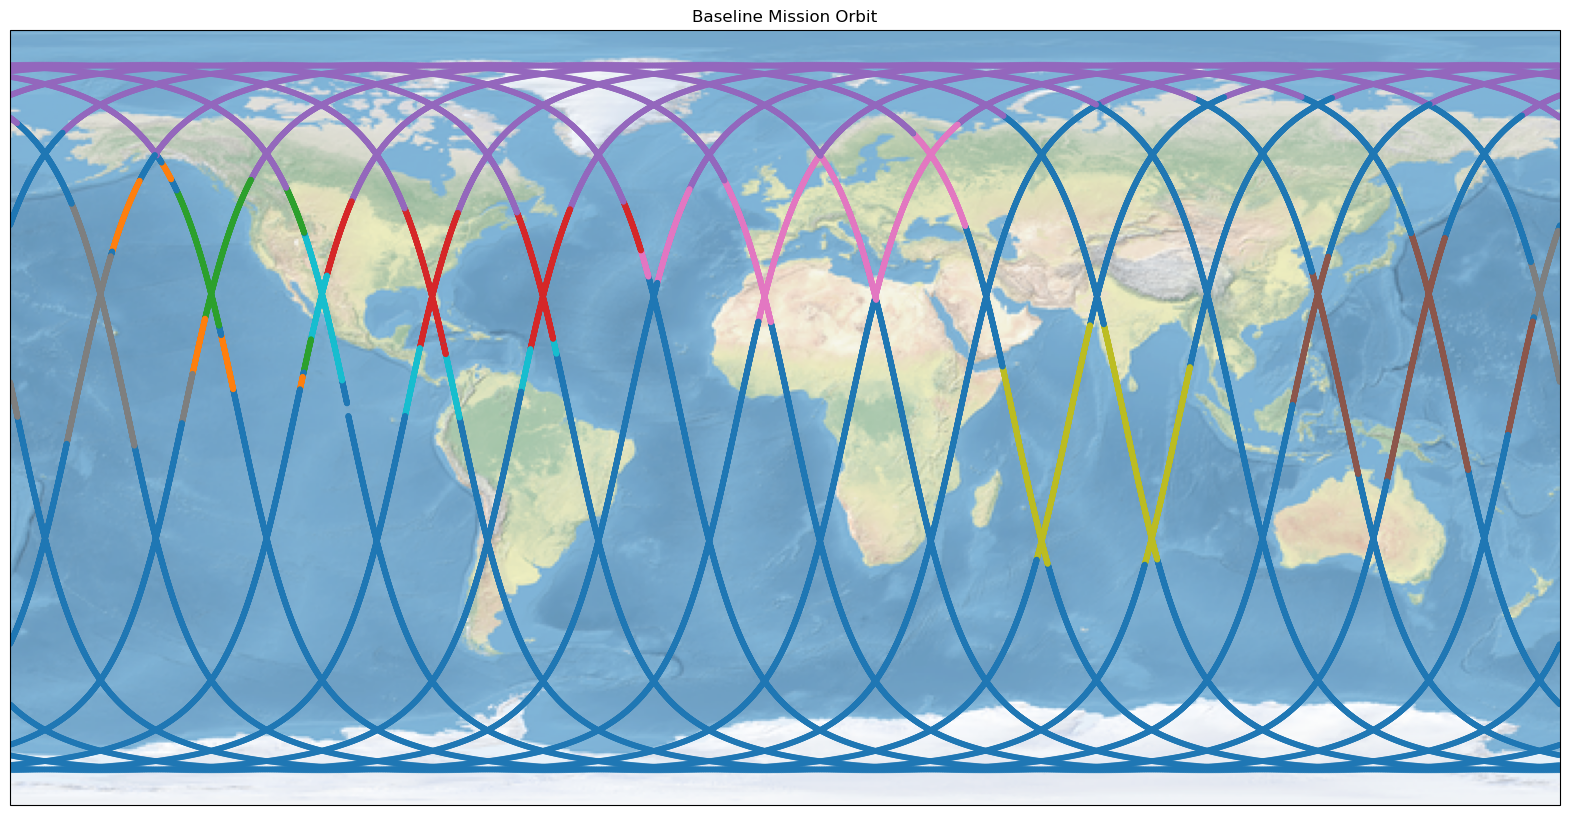

In [25]:
plot_orbits(fsw_df, "Baseline Mission Orbit")